Shapes, gradients, text and nested groups with document shortcuts.

Run it as ``python basic_shapes.py [OUTPUT_DIR]`` or open ``basic_shapes.ipynb`` to see each step.

In [1]:
import sys
import tempfile
from pathlib import Path

import svgwriter as svg

A `Document` has shortcuts (`rect`, `circle`, `text`, ...) that create a shape, add it and return it.
Gradients are values you pass as `fill`.

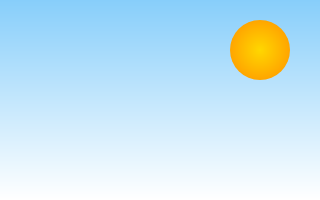

In [2]:
WIDTH, HEIGHT = 320, 200
doc = svg.Document(WIDTH, HEIGHT)
doc.title("Basic shapes")
sky = svg.LinearGradient.vertical("lightskyblue", "white")
sun = doc.radial_gradient(svg.Stop(0, "gold"), svg.Stop(1, "orange"), cx=0.5, cy=0.5, r=0.5)

doc.rect(0, 0, WIDTH, HEIGHT, fill=sky)
doc.circle(260, 50, 30, fill=sun)
doc

`doc.group(...)` is a context manager: shapes added inside share its style and transform,
and groups nest.

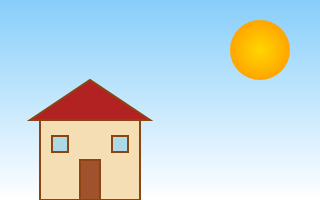

In [3]:
with doc.group(id="house", stroke="saddlebrown", stroke_width=2, transform="translate(40 80)") as house:
    doc.rect(0, 40, 100, 80, fill="wheat")
    doc.polygon([(-10, 40), (50, 0), (110, 40)], fill="firebrick")
    doc.rect(40, 80, 20, 40, fill="sienna")
    with house.group(fill="lightblue"):
        doc.rect(12, 56, 16, 16)
        doc.rect(72, 56, 16, 16)
doc

Standalone shapes (`svg.ellipse`, `svg.line`) are added with `+=`. Text takes styled `span`s.

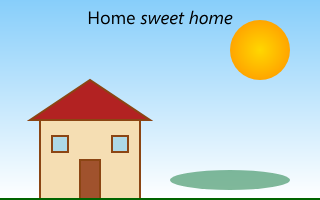

In [4]:
doc += [
    svg.ellipse(230, 180, 60, 10, fill="seagreen", opacity=0.6),
    svg.line(0, 199, WIDTH, 199, stroke="darkgreen", stroke_width=2),
]
title = doc.text("Home", x=WIDTH / 2, y=24, text_anchor="middle", font_family="sans-serif", font_size=18)
title.span(" sweet home", font_style="italic")
doc

Save it. Pass a folder as the first argument to choose where the file goes.

In [5]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
doc.save(out / "basic_shapes.svg")
print("saved basic_shapes.svg")

saved basic_shapes.svg
